# Basic TPS Setup with Host-Guest System

This notebook demonstrates how to set up and run a basic TPS simulation using ops-setup with a host-guest system.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import openpathsampling as paths
from openpathsampling.experimental.storage import monkey_patch_all
from openpathsampling.experimental.storage.collective_variables import MDTrajFunctionCV
from openpathsampling.experimental.storage import Storage
paths = monkey_patch_all(paths)

# Import from ops-setup
from ops_setup.systems.examples.host_guest import HostGuestTPSSetup
from ops_setup.systems.examples.host_guest import transform_functions
from ops_setup.engines.openmm_sampling import load_initial_trajectory

****** PyMBAR will use 64-bit JAX! *******
* JAX is currently set to 32-bit bitsize *
* which is its default.                  *
*                                        *
* PyMBAR requires 64-bit mode and WILL   *
* enable JAX's 64-bit mode when called.  *
*                                        *
* This MAY cause problems with other     *
* Uses of JAX in the same code.          *
******************************************



## 1. Create the TPS Setup

In [2]:
# Setup TPS for host guest sytstem using shorter state definitions to look at a very small part of the transition
config_path = Path("/home/rbreeba/code/ops-setup/examples/config_files/TPS_template_host_guest_test.json")

tps_setup = HostGuestTPSSetup(config_path=config_path,
                              cv_function=transform_functions.cv_hg_distance 

                              )

print(f"System: {tps_setup.system_name}")
print(f"MD Engine: {tps_setup.md_engine.name}")
print(f"States: {tps_setup.states}")

system_name: CB7-B2
platform_name: CPU
UNITS: 
    size_unit: nanometer
    press_unit: bar
    temp_unit: kelvin
    time_unit: picosecond
Integrator_settings: 
    temperature: 298.15
    pressure: 1.0
    dt: 0.002
    friction: 1.0
    barostat_frequency: 25
    constant_variable: P
TPS_settings: 
    n_frames_max: 5000
    n_steps_per_frame: 10
    shooting_scheme: TwoWay
    selector: uniform
    selector_params: 
        width: 0.1
        origin_shift: 0.0
system_files: 
    resource_directory: /home/rbreeba/code/ops-setup/examples/resource_files/host_guest/
    topology_file: complex-explicit.prmtop
    coordinate_file: complex-explicit.inpcrd
    state_file: cb7_b2_mdV_cont2.state
system_parameters: 
    nonbonded_cutoff: 1.0
    ewald_tolerance: 0.0005
States: 
    bound: 0.2
    unbound: 0.55
settings: 
extracting config
Setting up VVVR integrator...
Extracting topology and creating system from AMBER files...
Creating snapshot template...
Setting up VVVR integrator...
Setti

## 3. Create Initial Trajectory

We need an initial path that goes from state A to state B.

In [3]:
# Set engine for path movers
paths.PathMover.engine = tps_setup.md_engine

# Create a simple initial trajectory
print("Creating initial trajectory...")
init_traj_path = Path("/home/rbreeba/Projects/-RE-TIS-AIMMD/TIS_AIMMD_biosystems/Host-Guest-System-NPT/CarbonResults/Run_Bound_Unbound_05_100/final_TPS_traj.db")
# init_traj_path = Path(tps_setup.config["system_files"]["resource_directory"]) / "initialPathNPT.db"
init_traj = load_initial_trajectory(init_traj_path)
print(f"First frame: {init_traj[0].coordinates}")
print(f"Last frame: {init_traj[-1].coordinates}")

Creating initial trajectory...
First frame: [[ 3.2392025   3.8456097   1.7952275 ]
 [ 3.3058922   4.0776625   1.7157667 ]
 [ 3.0575213   3.9189024   1.8678575 ]
 ...
 [ 0.8899219  -3.1450667   5.775356  ]
 [ 0.9828945  -3.162649    5.760889  ]
 [ 0.88559806 -3.1110785   5.8647337 ]] nm
Last frame: [[ 2.8497941  3.4933555  2.2325451]
 [ 2.9208121  3.7115924  2.1417017]
 [ 2.6471174  3.528594   2.1608868]
 ...
 [ 0.3599795 -4.415555   5.5888076]
 [ 0.3071893 -4.3847394  5.6624684]
 [ 0.3020914 -4.4749784  5.5410566]] nm


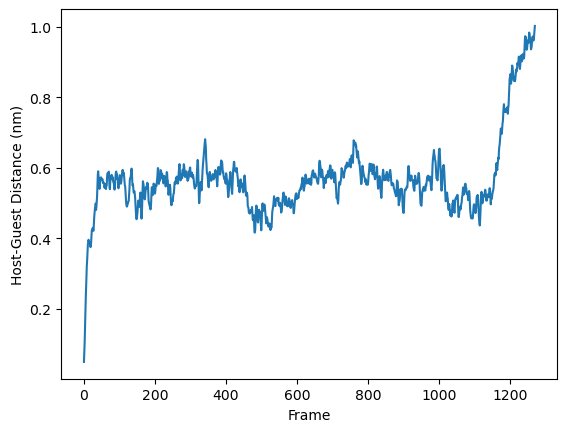

In [4]:
fig, ax = plt.subplots()
distances = transform_functions.cv_hg_distance(init_traj)
ax.plot(distances)
ax.set_xlabel("Frame")
ax.set_ylabel("Host-Guest Distance (nm)")
plt.show()

## 4. Create TPS Network and Move Scheme

In [5]:

tps_setup._create_selector(selector_type="gaussian", collectivevariable=transform_functions.cv_hg_distance, gaussian_width=0.1, origin_shift=0.5) 

In [6]:
# Get the stable states
stateA, stateB = tps_setup.states

# Create TPS network
network = paths.TPSNetwork.from_states_all_to_all(tps_setup.states)
    
print(f"Network: {network}")

# Create one-way shooting move scheme
move_scheme = tps_setup.create_move_scheme(network, scheme_type="TwoWay")
print(f"Move scheme: {move_scheme}")

Network: <openpathsampling.high_level.network.TPSNetwork object at 0x7f16245d7710>
Move scheme: <openpathsampling.high_level.move_scheme.MoveScheme object at 0x7f16243eab50>


## 5. Initialize Sampling

In [7]:
# Create storage for the simulation
storage_file = f"storages/host_guest_tps_example_{tps_setup.system_name}.db"

storage = Storage(storage_file, "w")

# Save the engine, network, and move scheme
storage.save(tps_setup.md_engine)
storage.save(tps_setup.template)
storage.save(move_scheme)
storage.save(network)

print(f"Storage created: {storage_file}")

Storage created: storages/host_guest_tps_example_CB7-B2.db


## 6. Create Initial Conditions and Run TPS

In [8]:
# Create initial conditions from trajectory
initial_conditions = move_scheme.initial_conditions_from_trajectories(init_traj)

# Sanity check
initial_conditions.sanity_check()
print("Initial conditions sanity check passed!")

# Create sampler
sampler = paths.PathSampling(storage, move_scheme, initial_conditions)


No missing ensembles.
No extra ensembles.
Initial conditions sanity check passed!


In [9]:
from ops_setup.descriptor_storage import DescriptorStorage, sampling_descriptor_manager

# Create new storage - now using the improved function from ops_setup
descriptor_storage_path = Path("storages/descriptor_storage_host_guest_tps_test")

# Example 1: Using dictionary of CV functions (explicit names)
# sampling_descriptor_manager(
#     descriptor_storage_path=descriptor_storage_path,
#     sampler=sampler,
#     ops_storage=storage,
#     cv_functions={
#         'distance': transform_functions.cv_hg_distance,
#         'position_angle': transform_functions.cv_hg_position_angle_symmetric,
#     },
#     n_steps=10,
#     increment_steps=3,
#     # start_index auto-detected from existing storage!
# )

### Alternative: Using multi-dimensional descriptor_transform

The new `sampling_descriptor_manager` can also handle descriptor_transform functions that return multiple descriptors at once:

In [10]:
print([transform_functions.descriptor_labels_new[label_idx] for label_idx in transform_functions.descriptors_index_7_set_from_14])

['Host-Guest Distance', 'Guest Orientation Angle', 'Guest Position Angle', 'Hydrogen Bonds', 'Waters in Cavity', 'Hydrophobic Contact Score', 'Shared Waters']


In [11]:
# Example 2: Using descriptor_transform with named dimensions
# This would work with descriptor_transform_HG_simple_symmetriced which returns (5,) array
sampling_descriptor_manager(
    descriptor_storage_path=descriptor_storage_path,
    sampler=sampler,
    ops_storage=storage,
    cv_functions=transform_functions.descriptor_transform_HG_continuous_waters_7_descriptors_symmetriced_or,
    descriptor_names=[transform_functions.descriptor_labels_new[label_idx] for label_idx in transform_functions.descriptors_index_7_set_from_14],
    n_steps=10,
    increment_steps=5,
)

Working on Monte Carlo cycle number 10
Running for 4 minutes 44 seconds - 71.05 seconds per step
Estimated time remaining: 1 minute 11 seconds
DONE! Completed 10 Monte Carlo cycles.


## 7. Analyze Results

In [12]:
# Extract trajectories
trajectories = [step.active[0].trajectory for step in storage.steps[:]]

print(f"Number of trajectories: {len(trajectories)}")
print(f"\nTrajectory lengths:")
for i, traj in enumerate(trajectories[:]):
    print(f"  Trajectory {i}: {len(traj)} snapshots")

Number of trajectories: 11

Trajectory lengths:
  Trajectory 0: 35 snapshots
  Trajectory 1: 35 snapshots
  Trajectory 2: 35 snapshots
  Trajectory 3: 35 snapshots
  Trajectory 4: 35 snapshots
  Trajectory 5: 35 snapshots
  Trajectory 6: 35 snapshots
  Trajectory 7: 35 snapshots
  Trajectory 8: 35 snapshots
  Trajectory 9: 35 snapshots
  Trajectory 10: 35 snapshots


## 8. Plot Sample Trajectories from OPS storage

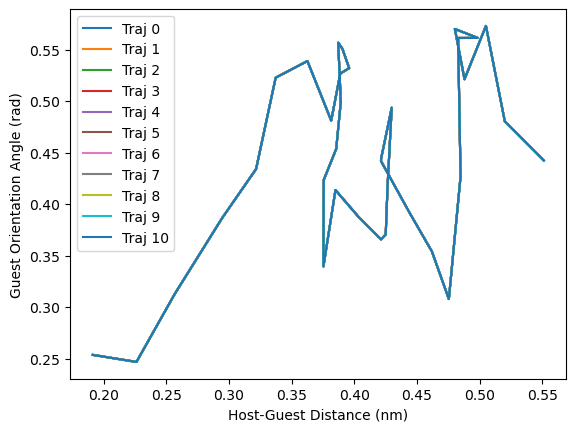

In [13]:
# Plot the host-guest distance for each trajectory
fig, ax = plt.subplots()
for i, traj in enumerate(trajectories[:]):
    distances = transform_functions.cv_hg_distance(traj)
    angle = transform_functions.cv_hg_angle_guest_orientation_symmetric(traj)
    ax.plot(distances, angle,label=f"Traj {i}")
ax.set_xlabel("Host-Guest Distance (nm)")
ax.set_ylabel("Guest Orientation Angle (rad)")
ax.legend()
plt.show()

## 9. Plot sampling trajectory from descriptor storage


Descriptor Storage Summary
Method Type: unknown
Descriptor Types: Host-Guest Distance, Guest Orientation Angle, Guest Position Angle, Hydrogen Bonds, Waters in Cavity, Hydrophobic Contact Score, Shared Waters

Set: TPS
  λ=0.00:   10 trajectories,     350 points [weights:  ]

Total: 10 trajectories, 350 points
{'Host-Guest Distance': 1, 'Guest Orientation Angle': 1, 'Guest Position Angle': 1, 'Hydrogen Bonds': 1, 'Waters in Cavity': 1, 'Hydrophobic Contact Score': 1, 'Shared Waters': 1}
(35, 2)
(35, 2)
(35, 2)
(35, 2)
(35, 2)
(35, 2)
(35, 2)
(35, 2)
(35, 2)


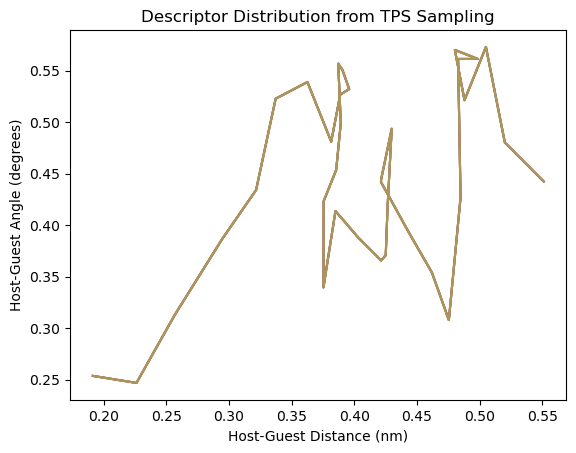

In [17]:

desc_storage = DescriptorStorage.load(descriptor_storage_path, mode='r')
print(desc_storage.summary())
print(desc_storage.metadata["descriptor_dims"])
fig, ax= plt.subplots()
for traj in range(1, 10):  # Assuming we have 5 sampled trajectories stored with indices 1-5

    traj_desc = desc_storage.get_trajectory_descriptors(set_name='TPS', interface_value=0.0, trajectory_index=traj, descriptor_names=['Host-Guest Distance', 'Guest Orientation Angle'])
    print(np.shape(traj_desc))
    ax.plot(traj_desc[:,0], traj_desc[:,1], markersize=2, alpha=0.5)
ax.set_xlabel("Host-Guest Distance (nm)")
ax.set_ylabel("Host-Guest Angle (degrees)")
ax.set_title("Descriptor Distribution from TPS Sampling")
plt.show()

## 10. Clean Up

In [18]:
# Close storage
storage.close()
print(f"Storage closed: {storage_file}")

Storage closed: storages/host_guest_tps_example_CB7-B2.db
